In [1]:
%pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 3.7 MB/s eta 0:00:0000:0100:010m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 10.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 3.9 MB/s eta 0:00:0000:0100:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 1.2 MB/s eta 0:00:00a 0:00:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 7.0 MB/s eta 0:00:0000:0100:01m

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# S3 - Procesamiento y calidad de datos: filtrado, duplicados, nulos y particionamiento
**Proyecto Sello · Equipo 10 BIG IMPACT · Predicción de heladas en Juliaca**

Objetivo: dejar el histórico por hora (2010 – 01-Oct-2026) validado y escrito en Parquet particionado, listo para el modelo de S4.

## 0. Arquitectura por capas (Bronze → Silver → Gold)

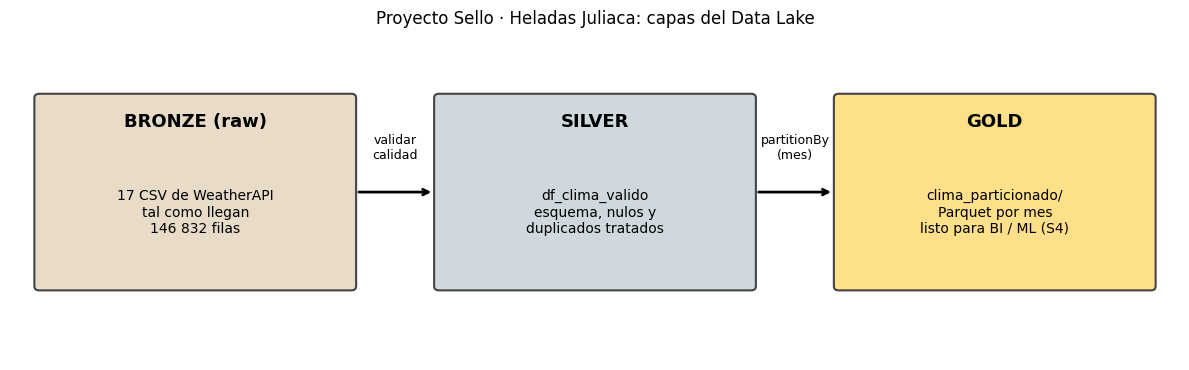

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.set_xlim(0, 12); ax.set_ylim(0, 4); ax.axis("off")

capas = [
    (0.3, "#e8dcc8", "BRONZE (raw)", "17 CSV de WeatherAPI\ntal como llegan\n146 832 filas"),
    (4.4, "#cfd8dc", "SILVER", "df_clima_valido\nesquema, nulos y\nduplicados tratados"),
    (8.5, "#ffe08a", "GOLD", "clima_particionado/\nParquet por mes\nlisto para BI / ML (S4)"),
]
for x, color, titulo, texto in capas:
    ax.add_patch(FancyBboxPatch((x, 0.9), 3.2, 2.3, boxstyle="round,pad=0.05",
                                fc=color, ec="#444", lw=1.5))
    ax.text(x + 1.6, 2.85, titulo, ha="center", fontsize=13, fontweight="bold")
    ax.text(x + 1.6, 1.8, texto, ha="center", va="center", fontsize=10)

for x0, x1, txt in [(3.55, 4.35, "validar\ncalidad"), (7.65, 8.45, "partitionBy\n(mes)")]:
    ax.annotate("", xy=(x1, 2.05), xytext=(x0, 2.05),
                arrowprops=dict(arrowstyle="->", lw=2))
    ax.text((x0 + x1) / 2, 2.45, txt, ha="center", fontsize=9)

ax.set_title("Proyecto Sello · Heladas Juliaca: capas del Data Lake", fontsize=12)
plt.tight_layout()
plt.show()

## 1. Crear la SparkSession

In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion3-calidad-datos")
    .master("local[*]")
    .config("spark.ui.port", "4040")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 02:19:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/20 02:19:32 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/20 02:19:32 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


### 1.1 Rutas del proyecto
`ORIGEN_DATOS` es la capa Bronze: los CSV originales de S1, sin tocar. `ARTIFACTS` es donde se escribirán las capas Silver y Gold.

In [4]:
ORIGEN_DATOS = "/opt/u1/s01-arquitectura/data/historico"
ARTIFACTS = "/opt/u1/s03-calidad-particionamiento/artifacts"

print("Bronze (origen):", ORIGEN_DATOS)
print("Salidas (artifacts):", ARTIFACTS)

Bronze (origen): /opt/u1/s01-arquitectura/data/historico
Salidas (artifacts): /opt/u1/s03-calidad-particionamiento/artifacts


## 2. Cargar el histórico (Bronze) y validar el esquema
### 2.1 Esquema explícito
Control de calidad #1: el tipo de cada columna lo decido yo, no Spark. Así `hora` llega como timestamp y los valores numéricos no se confunden con texto.

In [5]:
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType, IntegerType, TimestampType
)

schema_clima = StructType([
    StructField("ciudad", StringType(), nullable=True),
    StructField("hora", TimestampType(), nullable=True),
    StructField("temperatura", DoubleType(), nullable=True),
    StructField("puntoRocio", DoubleType(), nullable=True),
    StructField("humedad", IntegerType(), nullable=True),
    StructField("nubosidad", IntegerType(), nullable=True),
    StructField("presion", DoubleType(), nullable=True),
    StructField("precipitacion", DoubleType(), nullable=True),
])

df_clima = spark.read.csv(ORIGEN_DATOS, header=True, schema=schema_clima)

df_clima.printSchema()

root
 |-- ciudad: string (nullable = true)
 |-- hora: timestamp (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: integer (nullable = true)
 |-- nubosidad: integer (nullable = true)
 |-- presion: double (nullable = true)
 |-- precipitacion: double (nullable = true)



### 2.2 Validar que las columnas requeridas existan
Un esquema confirma el tipo, no la presencia: un CSV con una columna renombrada igual carga, con esa columna entera en nulo. Si falta alguna, el pipeline se detiene con un error claro.

In [6]:
columnas_requeridas = {
    "ciudad", "hora", "temperatura", "puntoRocio",
    "humedad", "nubosidad", "presion", "precipitacion",
}

faltantes = columnas_requeridas - set(df_clima.columns)
if faltantes:
    raise ValueError(f"Faltan columnas obligatorias: {sorted(faltantes)}")

print("Esquema validado: las 8 columnas requeridas están presentes.")

Esquema validado: las 8 columnas requeridas están presentes.


### 2.3 Conteo de filas (línea base)
Este número es la referencia para confirmar que ningún paso posterior pierda o duplique filas.

In [7]:
print(df_clima.columns)

total_filas = df_clima.count()
print("Filas:", total_filas, "| Columnas:", len(df_clima.columns))

['ciudad', 'hora', 'temperatura', 'puntoRocio', 'humedad', 'nubosidad', 'presion', 'precipitacion']


Filas: 146832 | Columnas: 8


### 2.4 Gráfico: volumen de lecturas por año
Un año con muchas menos lecturas que los demás indicaría datos perdidos en silencio, como en el caso de Public Health England. 2026 es menor porque el histórico termina el 01-Oct-2026.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


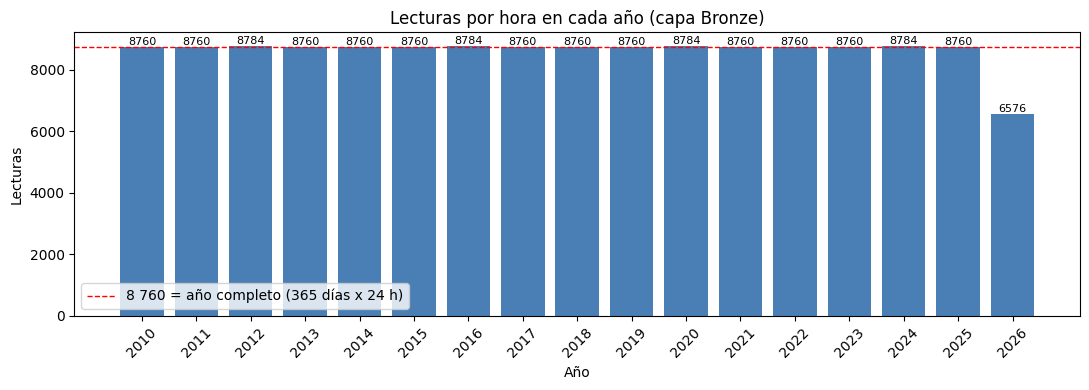

In [8]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import year, col, count

df_anios = (
    df_clima.groupBy(year(col("hora")).alias("anio"))
    .agg(count("*").alias("lecturas"))
    .orderBy("anio")
    .toPandas()
)

fig, ax = plt.subplots(figsize=(11, 4))
barras = ax.bar(df_anios["anio"].astype(str), df_anios["lecturas"], color="#4a7fb5")
ax.axhline(8760, color="red", linestyle="--", linewidth=1, label="8 760 = año completo (365 días x 24 h)")
ax.bar_label(barras, fontsize=8)
ax.set_title("Lecturas por hora en cada año (capa Bronze)")
ax.set_xlabel("Año"); ax.set_ylabel("Lecturas")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Explorar nulos por columna
Un nulo no es automáticamente un error: puede ser un dato legítimamente ausente o una falla de captura. Antes de tratarlo hay que contarlo, columna por columna.
### 3.1 Conteo de nulos

In [9]:
from pyspark.sql.functions import col, count, when

df_clima.select([
    count(when(col(c).isNull(), c)).alias(c) for c in df_clima.columns
]).show(vertical=True, truncate=False)

-RECORD 0------------
 ciudad        | 0   
 hora          | 0   
 temperatura   | 0   
 puntoRocio    | 0   
 humedad       | 0   
 nubosidad     | 0   
 presion       | 0   
 precipitacion | 0   



### 3.2 Nulos con porcentaje sobre el total

In [10]:
nulos = df_clima.select([
    count(when(col(c).isNull(), c)).alias(c) for c in df_clima.columns
]).collect()[0].asDict()

for columna, cantidad in nulos.items():
    porcentaje = cantidad / total_filas * 100
    print(f"{columna}: {cantidad} nulos ({porcentaje:.2f}%)")

ciudad: 0 nulos (0.00%)
hora: 0 nulos (0.00%)
temperatura: 0 nulos (0.00%)
puntoRocio: 0 nulos (0.00%)
humedad: 0 nulos (0.00%)
nubosidad: 0 nulos (0.00%)
presion: 0 nulos (0.00%)
precipitacion: 0 nulos (0.00%)


### 3.3 Cadenas vacías y valores imposibles
`isNull()` no detecta cadenas vacías ni espacios. Se confirma sobre `ciudad` y se revisan rangos físicamente razonables en las variables del proyecto.

In [11]:
from pyspark.sql.functions import trim

print("ciudad nula o vacía:", df_clima.filter(col("ciudad").isNull() | (trim(col("ciudad")) == "")).count())
print("humedad fuera de 0-100:", df_clima.filter((col("humedad") < 0) | (col("humedad") > 100)).count())
print("nubosidad fuera de 0-100:", df_clima.filter((col("nubosidad") < 0) | (col("nubosidad") > 100)).count())
print("temperatura fuera de -30 a 40:", df_clima.filter((col("temperatura") < -30) | (col("temperatura") > 40)).count())

ciudad nula o vacía: 0
humedad fuera de 0-100: 0
nubosidad fuera de 0-100: 0
temperatura fuera de -30 a 40: 0


### 3.4 Gráfico: porcentaje de nulos por columna

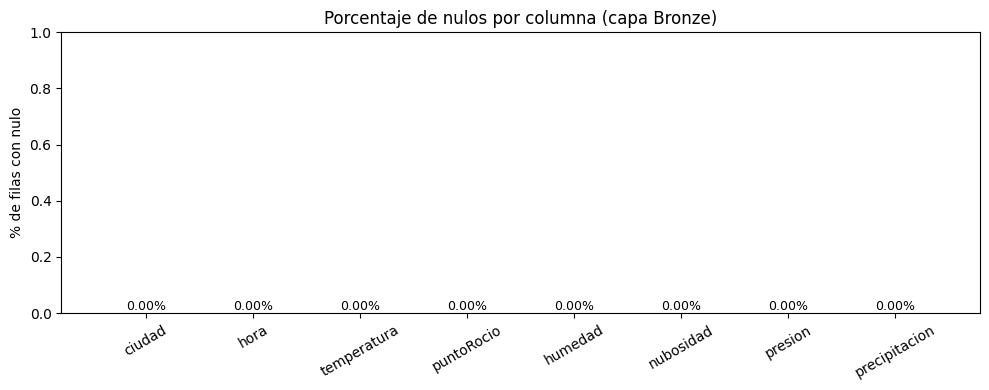

In [12]:
import matplotlib.pyplot as plt

columnas = list(nulos.keys())
porcentajes = [nulos[c] / total_filas * 100 for c in columnas]

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(columnas, porcentajes, color="#c0504d")
ax.bar_label(barras, fmt="%.2f%%", fontsize=9)
ax.set_ylim(0, max(max(porcentajes) * 1.3, 1))
ax.set_title("Porcentaje de nulos por columna (capa Bronze)")
ax.set_ylabel("% de filas con nulo")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Filtrado de datos (filter / where)
Dos formas equivalentes de escribir un filtro: expresión SQL como texto y expresión con `col()`. Las condiciones se combinan con `&`, `|` y `~`, nunca con `and`/`or`/`not` de Python.
### 4.1 Expresión SQL como texto

In [13]:
df_clima.filter("temperatura <= 0").show(5)
df_clima.filter("humedad BETWEEN 40 AND 60").show(5)

+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2016-04-24 03:00:00|       -0.1|      -6.7|     61|        4| 1022.0|          0.0|
|Juliaca|2016-04-25 02:00:00|       -0.2|      -9.3|     50|        0| 1021.0|          0.0|
|Juliaca|2016-04-25 03:00:00|       -0.7|      -9.5|     51|        0| 1020.0|          0.0|
|Juliaca|2016-04-25 04:00:00|       -0.4|      -9.6|     46|        0| 1021.0|          0.0|
|Juliaca|2016-04-25 06:00:00|       -0.2|      -9.9|     37|        0| 1023.0|          0.0|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
only showing top 5 rows
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|punto

### 4.2 La misma lógica con col()

In [14]:
from pyspark.sql.functions import col

df_clima.filter(col("temperatura") <= 0).show(5)
df_clima.filter(col("humedad").between(40, 60)).show(5)
df_clima.filter((col("temperatura") <= 0) & (col("nubosidad") < 20)).show(5)

+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2016-04-24 03:00:00|       -0.1|      -6.7|     61|        4| 1022.0|          0.0|
|Juliaca|2016-04-25 02:00:00|       -0.2|      -9.3|     50|        0| 1021.0|          0.0|
|Juliaca|2016-04-25 03:00:00|       -0.7|      -9.5|     51|        0| 1020.0|          0.0|
|Juliaca|2016-04-25 04:00:00|       -0.4|      -9.6|     46|        0| 1021.0|          0.0|
|Juliaca|2016-04-25 06:00:00|       -0.2|      -9.9|     37|        0| 1023.0|          0.0|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
only showing top 5 rows
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|punto

### 4.3 Trampa: `.between()` incluye los extremos
`.between(-1, 1)` equivale a `BETWEEN -1 AND 1` e incluye ambos extremos. Una comparación estricta escrita a mano los excluye, así que no es la misma consulta. En heladas importa: el umbral es justo `<= 0`.

In [15]:
print("between (incluye -1 y 1):", df_clima.filter(col("temperatura").between(-1, 1)).count())
print("estricto (excluye -1 y 1):", df_clima.filter((col("temperatura") > -1) & (col("temperatura") < 1)).count())
print("exactamente 0.0 °C:", df_clima.filter(col("temperatura") == 0).count())
print("temperatura < 0 (estricto):", df_clima.filter(col("temperatura") < 0).count())
print("temperatura <= 0 (umbral de helada):", df_clima.filter(col("temperatura") <= 0).count())

between (incluye -1 y 1): 5149
estricto (excluye -1 y 1): 4654
exactamente 0.0 °C: 235
temperatura < 0 (estricto): 2945
temperatura <= 0 (umbral de helada): 3180


### 4.4 where() es un alias de filter()

In [16]:
df_clima.where(col("nubosidad") == 0).show(5)
df_clima.where("temperatura <= 0 AND humedad > 80").show(5)

+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2016-01-01 08:00:00|       11.6|      -1.8|     40|        0| 1017.0|          0.0|
|Juliaca|2016-01-01 09:00:00|       12.9|      -1.9|     36|        0| 1016.0|          0.0|
|Juliaca|2016-01-01 10:00:00|       14.1|      -3.4|     30|        0| 1015.0|          0.0|
|Juliaca|2016-01-01 11:00:00|       15.3|      -5.0|     25|        0| 1013.0|          0.0|
|Juliaca|2016-01-01 12:00:00|       16.5|      -6.5|     20|        0| 1012.0|          0.0|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
only showing top 5 rows
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|punto

### 4.5 Gráfico: distribución de la temperatura y el umbral de helada
La línea roja es el umbral de 0 °C. Todo lo que queda a su izquierda es lo que `filter(temperatura <= 0)` selecciona.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


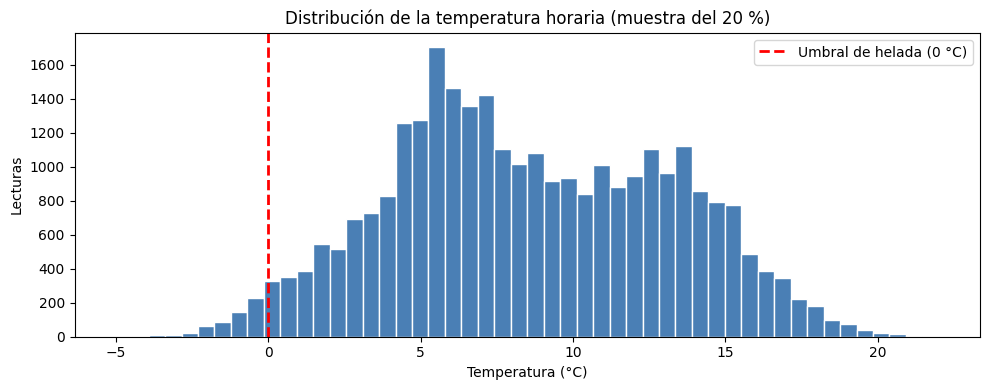

In [17]:
import matplotlib.pyplot as plt

temps = df_clima.select("temperatura").sample(fraction=0.2, seed=42).toPandas()["temperatura"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(temps, bins=50, color="#4a7fb5", edgecolor="white")
ax.axvline(0, color="red", linestyle="--", linewidth=2, label="Umbral de helada (0 °C)")
ax.set_title("Distribución de la temperatura horaria (muestra del 20 %)")
ax.set_xlabel("Temperatura (°C)"); ax.set_ylabel("Lecturas")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Ordenar resultados (orderBy / sort)
`orderBy()` ordena todo el DataFrame y obliga a Spark a barajar los datos entre particiones, así que es una operación cara. Se aplica sobre el resultado final, no como paso intermedio.
### 5.1 Una columna: formas equivalentes

In [18]:
df_clima.orderBy("temperatura").show(3)
df_clima.orderBy(col("temperatura").desc()).show(3)
df_clima.orderBy("temperatura", ascending=False).show(3)

+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2015-07-08 06:00:00|       -5.4|     -22.4|     18|        0| 1024.0|          0.0|
|Juliaca|2010-07-19 06:00:00|       -5.3|     -25.5|     14|        0| 1025.0|          0.0|
|Juliaca|2015-07-08 05:00:00|       -5.3|     -21.6|     20|        0| 1023.0|          0.0|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
only showing top 3 rows
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2022-11-20 15:00:00|       22.0|     

### 5.2 Nulos explícitos y varias columnas
Los nulos no existen en este dataset, pero se deja explícito dónde irían. Con varias columnas, cada una puede tener su propio sentido de orden.

In [19]:
df_clima.orderBy(col("temperatura").asc_nulls_last()).show(3)
df_clima.orderBy(col("humedad").desc(), col("temperatura").asc()).show(3)
df_clima.orderBy(["humedad", "temperatura"], ascending=[False, True]).show(3)

+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2015-07-08 06:00:00|       -5.4|     -22.4|     18|        0| 1024.0|          0.0|
|Juliaca|2015-07-08 05:00:00|       -5.3|     -21.6|     20|        0| 1023.0|          0.0|
|Juliaca|2010-07-19 06:00:00|       -5.3|     -25.5|     14|        0| 1025.0|          0.0|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
only showing top 3 rows
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
| ciudad|               hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+
|Juliaca|2017-07-02 06:00:00|        0.1|     

### 5.3 Las 10 lecturas más frías del histórico
`sort()` es un alias exacto de `orderBy()`.

In [20]:
df_frias = df_clima.sort(col("temperatura").asc()).select("hora", "temperatura", "puntoRocio", "humedad", "nubosidad").limit(10)
df_frias.show(truncate=False)

+-------------------+-----------+----------+-------+---------+
|hora               |temperatura|puntoRocio|humedad|nubosidad|
+-------------------+-----------+----------+-------+---------+
|2015-07-08 06:00:00|-5.4       |-22.4     |18     |0        |
|2010-07-19 06:00:00|-5.3       |-25.5     |14     |0        |
|2015-07-08 05:00:00|-5.3       |-21.6     |20     |0        |
|2026-06-25 06:00:00|-5.2       |-20.7     |28     |0        |
|2015-07-08 04:00:00|-5.2       |-20.9     |22     |0        |
|2010-07-19 03:00:00|-5.0       |-20.8     |28     |0        |
|2015-07-09 06:00:00|-5.0       |-18.1     |23     |0        |
|2015-07-09 05:00:00|-4.9       |-19.3     |21     |0        |
|2026-06-25 05:00:00|-4.7       |-20.9     |27     |0        |
|2015-07-09 04:00:00|-4.7       |-20.6     |20     |0        |
+-------------------+-----------+----------+-------+---------+



### 5.4 Gráfico: las 10 lecturas más frías

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


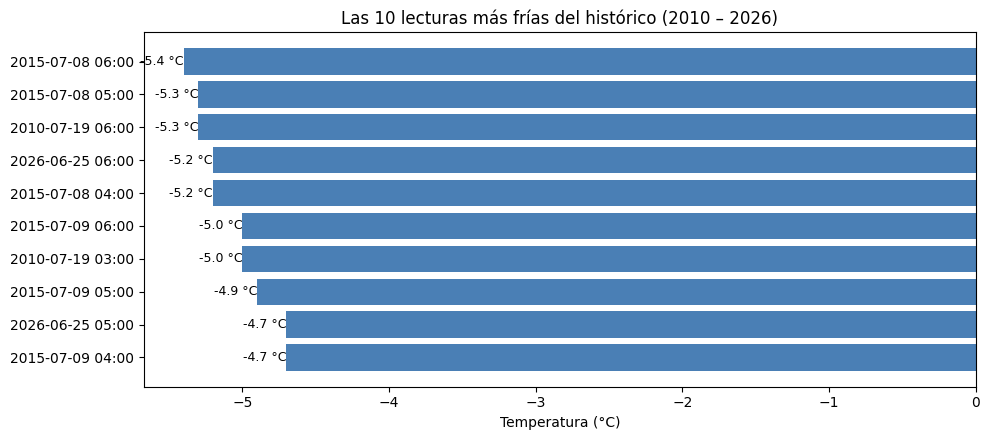

In [22]:
import matplotlib.pyplot as plt

pdf = df_frias.toPandas()
etiquetas = pdf["hora"].dt.strftime("%Y-%m-%d %H:%M")

fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(etiquetas[::-1], pdf["temperatura"][::-1], color="#4a7fb5")
ax.bar_label(barras, fmt="%.1f °C", fontsize=9)
ax.set_title("Las 10 lecturas más frías del histórico (2010 – 2026)")
ax.set_xlabel("Temperatura (°C)")
plt.tight_layout()
plt.show()

## 6. Tratamiento de duplicados
"Duplicado" depende de qué columnas se comparan. En este dataset la clave natural es (`ciudad`, `hora`): debe existir una sola lectura por hora.
### 6.1 Diagnóstico: filas completamente repetidas
`distinct()` y `dropDuplicates()` sin argumentos comparan todas las columnas.

In [23]:
total = df_clima.count()
sin_dup_todas = df_clima.dropDuplicates().count()
distinct_todas = df_clima.distinct().count()

print("Filas totales:            ", total)
print("dropDuplicates() (todas): ", sin_dup_todas)
print("distinct() (todas):       ", distinct_todas)
print("Filas repetidas exactas:  ", total - sin_dup_todas)

Filas totales:             146832
dropDuplicates() (todas):  146832
distinct() (todas):        146832
Filas repetidas exactas:   0


### 6.2 Diagnóstico por clave: groupBy + count
No elimina nada: lista los valores de la clave que aparecen más de una vez, para decidir después qué hacer.

In [24]:
from pyspark.sql.functions import col, count

df_dup_clave = (
    df_clima.groupBy("ciudad", "hora")
    .agg(count("*").alias("veces"))
    .filter(col("veces") > 1)
)

print("Claves (ciudad, hora) repetidas:", df_dup_clave.count())
df_dup_clave.orderBy("hora").show(10, truncate=False)

Claves (ciudad, hora) repetidas: 0
+------+----+-----+
|ciudad|hora|veces|
+------+----+-----+
+------+----+-----+



### 6.3 Unicidad de la clave con dropDuplicates(["ciudad", "hora"])
Se queda con una fila por combinación de clave, pero no controlo cuál.

In [25]:
sin_dup_clave = df_clima.dropDuplicates(["ciudad", "hora"]).count()
print("Filas con clave única:", sin_dup_clave)
print("Filas que sobran:     ", total - sin_dup_clave)

Filas con clave única: 146832
Filas que sobran:      0


### 6.4 Deduplicación determinista con Window + row_number()
Si hubiera claves repetidas, aquí **yo elijo** cuál conservar: la lectura con mayor `humedad`, y como desempate la de menor `temperatura`. Es el mismo patrón de la guía (`age` y `postal_code`).

In [26]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number

window_spec = Window.partitionBy("ciudad", "hora").orderBy(
    col("humedad").desc_nulls_last(),
    col("temperatura").asc_nulls_last(),
)

df_ranked = df_clima.withColumn("row_num", row_number().over(window_spec))
df_clima_dedup = df_ranked.filter(col("row_num") == 1).drop("row_num")

print("Antes:  ", df_clima.count())
print("Después:", df_clima_dedup.count())

Antes:   146832
Después: 146832


### 6.5 Gráfico: filas antes y después de cada técnica
Si todas las barras miden lo mismo, no había duplicados y las tres técnicas coinciden.

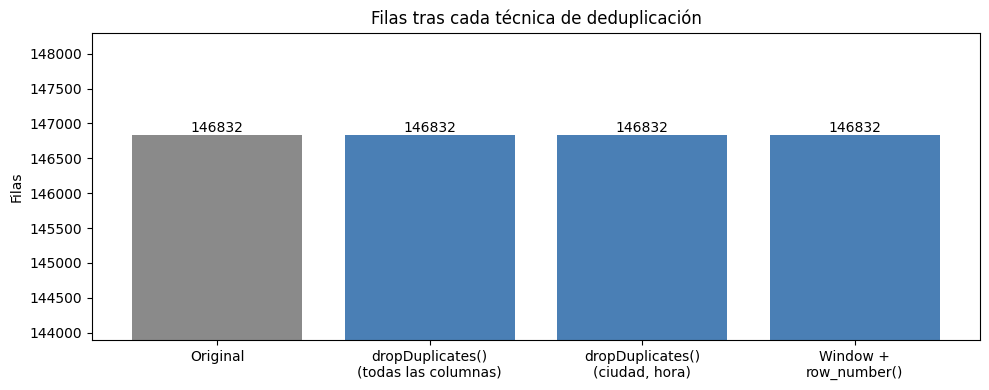

In [27]:
import matplotlib.pyplot as plt

etiquetas = ["Original", "dropDuplicates()\n(todas las columnas)", "dropDuplicates()\n(ciudad, hora)", "Window +\nrow_number()"]
valores = [total, sin_dup_todas, sin_dup_clave, df_clima_dedup.count()]

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(etiquetas, valores, color=["#8a8a8a", "#4a7fb5", "#4a7fb5", "#4a7fb5"])
ax.bar_label(barras, fontsize=10)
ax.set_ylim(min(valores) * 0.98, max(valores) * 1.01)
ax.set_title("Filas tras cada técnica de deduplicación")
ax.set_ylabel("Filas")
plt.tight_layout()
plt.show()

## 7. Tratar nulos y construir la capa Silver
### 7.1 Criterio de tratamiento por columna

| Columna | Si hubiera nulos | Decisión |
|---|---|---|
| `ciudad`, `hora` | La fila no se puede ubicar en el tiempo ni en el espacio | `na.drop(subset=[...])`: eliminar la fila |
| `temperatura` | Es la variable de la que se deriva la helada | `na.drop(subset=[...])`: eliminar la fila |
| `puntoRocio`, `humedad`, `nubosidad` | Predictores del modelo | **No rellenar** (rellenar con 0 inventaría un dato falso); se evalúa caso por caso |
| `presion`, `precipitacion` | Fuera del modelo (presión por sesgo entre fuentes, lluvia fuera del proyecto) | `na.fill(0)` sería aceptable, pero no se necesita |

Nunca se usa `.na.drop()` sin `subset`: elimina toda fila con cualquier nulo.

In [28]:
columnas_criticas = ["ciudad", "hora", "temperatura"]

df_clima_valido = df_clima_dedup.na.drop(subset=columnas_criticas)

print("Antes:  ", df_clima_dedup.count())
print("Después:", df_clima_valido.count())
assert df_clima_valido.count() == df_clima_dedup.count(), "Se perdieron filas al tratar nulos"
print("Control: ningún paso de calidad perdió filas. Esta es la capa Silver.")

Antes:   146832
Después: 146832
Control: ningún paso de calidad perdió filas. Esta es la capa Silver.


### 7.2 Demostración: qué pasaría si hubiera nulos (copia simulada)
Solo para entender el criterio. En una copia pequeña se vacía una columna de forma aleatoria y se compara `.na.drop()` sin argumentos contra `subset`. El dataset real no se modifica.

In [29]:
from pyspark.sql.functions import when, rand, col

df_demo = (
    df_clima_valido.limit(20000)
    .withColumn("humedad", when(rand(seed=1) < 0.30, None).otherwise(col("humedad")))
    .withColumn("nubosidad", when(rand(seed=2) < 0.30, None).otherwise(col("nubosidad")))
)

total_demo = df_demo.count()
drop_total = df_demo.na.drop().count()
drop_subset = df_demo.na.drop(subset=["temperatura"]).count()

print("Filas en la copia:                  ", total_demo)
print("na.drop() sin argumentos:           ", drop_total, f"({drop_total/total_demo*100:.1f}% conservado)")
print("na.drop(subset=['temperatura']):    ", drop_subset, f"({drop_subset/total_demo*100:.1f}% conservado)")

Filas en la copia:                   20000
na.drop() sin argumentos:            9768 (48.8% conservado)
na.drop(subset=['temperatura']):     20000 (100.0% conservado)


### 7.3 Gráfico: costo de `.na.drop()` sin criterio

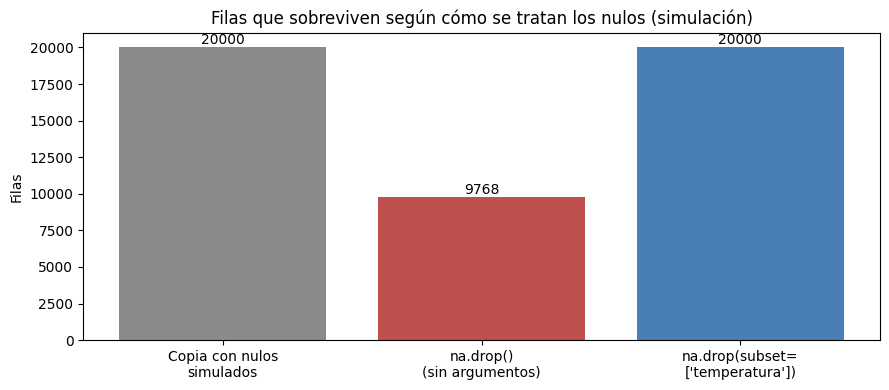

In [30]:
import matplotlib.pyplot as plt

etiquetas = ["Copia con nulos\nsimulados", "na.drop()\n(sin argumentos)", "na.drop(subset=\n['temperatura'])"]
valores = [total_demo, drop_total, drop_subset]

fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.bar(etiquetas, valores, color=["#8a8a8a", "#c0504d", "#4a7fb5"])
ax.bar_label(barras, fontsize=10)
ax.set_title("Filas que sobreviven según cómo se tratan los nulos (simulación)")
ax.set_ylabel("Filas")
plt.tight_layout()
plt.show()

## 8. Escritura en múltiples formatos
### 8.1 Columnas de partición (anio y mes)
`mes` es la columna de partición candidata: tiene solo 12 valores y es la que usa la pregunta de U1.

In [31]:
from pyspark.sql.functions import year, month, col

df_silver = (
    df_clima_valido
    .withColumn("anio", year(col("hora")))
    .withColumn("mes", month(col("hora")))
)

df_silver.printSchema()

root
 |-- ciudad: string (nullable = true)
 |-- hora: timestamp (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: integer (nullable = true)
 |-- nubosidad: integer (nullable = true)
 |-- presion: double (nullable = true)
 |-- precipitacion: double (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)



### 8.2 Escribir el mismo DataFrame en tres formatos
`.write.format(...).save(...)` es la forma genérica; solo cambia el nombre del formato. Spark escribe una **carpeta** con un archivo `part-` por partición, no un archivo suelto.

In [32]:
df_silver.write.format("csv").option("header", True).mode("overwrite").save(f"{ARTIFACTS}/formatos/silver_csv")
df_silver.write.format("json").mode("overwrite").save(f"{ARTIFACTS}/formatos/silver_json")
df_silver.write.format("parquet").mode("overwrite").save(f"{ARTIFACTS}/formatos/silver_parquet")

print("Escritura terminada")

Escritura terminada


### 8.3 Gráfico: tamaño en disco de cada formato
Parquet es columnar y comprimido; CSV y JSON son texto. La diferencia de tamaño es una de las razones por las que la capa Gold se guarda en Parquet.

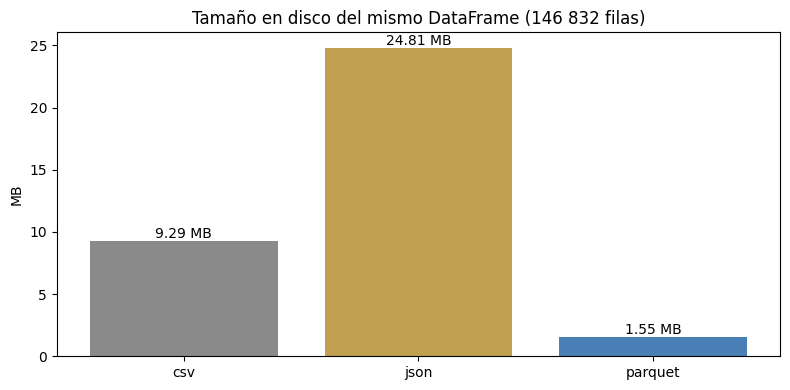

csv: 9.29 MB
json: 24.81 MB
parquet: 1.55 MB


In [33]:
import os
import matplotlib.pyplot as plt

def tamano_mb(ruta):
    total = 0
    for carpeta, _, archivos in os.walk(ruta):
        for a in archivos:
            total += os.path.getsize(os.path.join(carpeta, a))
    return total / 1024 / 1024

formatos = ["csv", "json", "parquet"]
tamanos = [tamano_mb(f"{ARTIFACTS}/formatos/silver_{f}") for f in formatos]

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(formatos, tamanos, color=["#8a8a8a", "#c0a050", "#4a7fb5"])
ax.bar_label(barras, fmt="%.2f MB", fontsize=10)
ax.set_title("Tamaño en disco del mismo DataFrame (146 832 filas)")
ax.set_ylabel("MB")
plt.tight_layout()
plt.show()

for f, t in zip(formatos, tamanos):
    print(f"{f}: {t:.2f} MB")

### 8.4 Archivos que Spark escribió
Cada `part-` es una partición del DataFrame en memoria. El número de archivos se hereda de esas particiones.

In [34]:
print("Particiones del DataFrame:", df_silver.rdd.getNumPartitions())
print(sorted(os.listdir(f"{ARTIFACTS}/formatos/silver_parquet")))

Particiones del DataFrame: 2
['._SUCCESS.crc', '.part-00000-58423ac8-ad67-4936-b7ab-44028508f0db-c000.snappy.parquet.crc', '.part-00001-58423ac8-ad67-4936-b7ab-44028508f0db-c000.snappy.parquet.crc', '_SUCCESS', 'part-00000-58423ac8-ad67-4936-b7ab-44028508f0db-c000.snappy.parquet', 'part-00001-58423ac8-ad67-4936-b7ab-44028508f0db-c000.snappy.parquet']


## 9. Escritura particionada en Parquet (Silver → Gold)
`partitionBy("mes")` no agrega una columna al archivo: crea **una subcarpeta por cada valor de `mes`**. Una consulta por un mes puede ignorar las otras 11 carpetas sin abrirlas.

`repartition("mes")` antes de escribir agrupa en memoria todas las filas del mismo mes en una sola partición, así cada carpeta recibe **un solo archivo** y no varios pequeños.

In [36]:
(
    df_silver
    .repartition("mes")
    .write
    .format("parquet")
    .mode("overwrite")
    .partitionBy("mes")
    .save(f"{ARTIFACTS}/clima_particionado")
)

print("Capa Gold escrita en:", f"{ARTIFACTS}/clima_particionado")

Capa Gold escrita en: /opt/u1/s03-calidad-particionamiento/artifacts/clima_particionado


### 9.1 Estructura de carpetas generada (árbol)

In [37]:
import os

raiz = f"{ARTIFACTS}/clima_particionado"
print("clima_particionado/")
for carpeta in sorted(os.listdir(raiz), key=lambda x: (not x.startswith("mes="), int(x.split("=")[1]) if x.startswith("mes=") else 0)):
    ruta = os.path.join(raiz, carpeta)
    if os.path.isdir(ruta):
        partes = [f for f in os.listdir(ruta) if f.endswith(".parquet")]
        print(f"├── {carpeta}/   ({len(partes)} archivo(s) parquet)")
    else:
        print(f"├── {carpeta}")

clima_particionado/
├── mes=1/   (1 archivo(s) parquet)
├── mes=2/   (1 archivo(s) parquet)
├── mes=3/   (1 archivo(s) parquet)
├── mes=4/   (1 archivo(s) parquet)
├── mes=5/   (1 archivo(s) parquet)
├── mes=6/   (1 archivo(s) parquet)
├── mes=7/   (1 archivo(s) parquet)
├── mes=8/   (1 archivo(s) parquet)
├── mes=9/   (1 archivo(s) parquet)
├── mes=10/   (1 archivo(s) parquet)
├── mes=11/   (1 archivo(s) parquet)
├── mes=12/   (1 archivo(s) parquet)
├── ._SUCCESS.crc
├── _SUCCESS


### 9.2 Gráfico: balance de filas por partición
Una buena columna de partición reparte los datos de forma equilibrada. Si una carpeta tuviera casi todo, `PartitionFilters` ayudaría poco.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


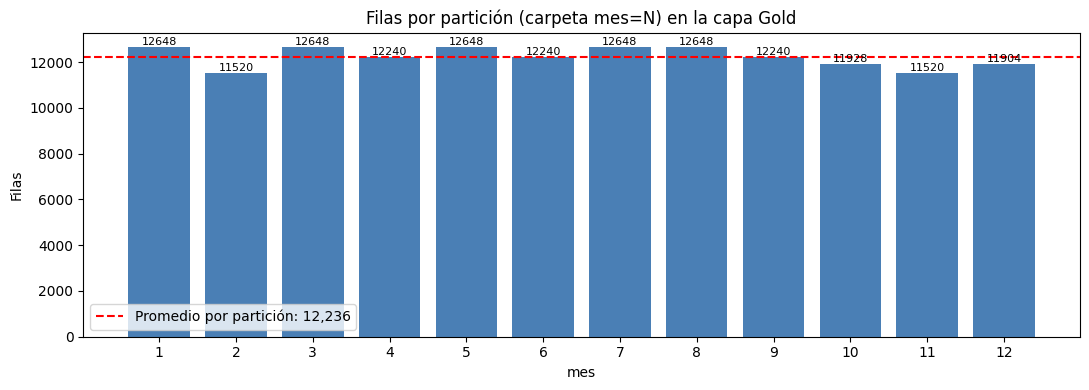

Mayor / menor partición: 12648 / 11520


In [38]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import count, col

df_balance = (
    df_silver.groupBy("mes")
    .agg(count("*").alias("filas"))
    .orderBy("mes")
    .toPandas()
)

media = df_balance["filas"].mean()

fig, ax = plt.subplots(figsize=(11, 4))
barras = ax.bar(df_balance["mes"].astype(str), df_balance["filas"], color="#4a7fb5")
ax.axhline(media, color="red", linestyle="--", label=f"Promedio por partición: {media:,.0f}")
ax.bar_label(barras, fontsize=8)
ax.set_title("Filas por partición (carpeta mes=N) en la capa Gold")
ax.set_xlabel("mes"); ax.set_ylabel("Filas")
ax.legend()
plt.tight_layout()
plt.show()

print("Mayor / menor partición:", df_balance["filas"].max(), "/", df_balance["filas"].min())

## 10. Leer de vuelta la capa Gold y verificar
Spark reconstruye la columna `mes` a partir del **nombre de la carpeta** (`mes=7`), no del contenido del archivo.
### 10.1 Conteo de ida y vuelta
Se confirma que escribir y volver a leer no perdió ni duplicó ninguna fila.

In [39]:
df_gold = spark.read.parquet(f"{ARTIFACTS}/clima_particionado")

print("Escrito (Silver):", df_silver.count())
print("Leído (Gold):    ", df_gold.count())

assert df_gold.count() == df_silver.count(), "El viaje de ida y vuelta perdió o duplicó filas"
print("Control: los conteos coinciden.")

df_gold.printSchema()

Escrito (Silver): 146832
Leído (Gold):     146832
Control: los conteos coinciden.
root
 |-- ciudad: string (nullable = true)
 |-- hora: timestamp (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: integer (nullable = true)
 |-- nubosidad: integer (nullable = true)
 |-- presion: double (nullable = true)
 |-- precipitacion: double (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)



### 10.2 Plan de ejecución: PartitionFilters
Si el filtro compara la columna de partición directamente, Spark salta carpetas enteras (*partition pruning*) sin abrir ningún archivo. Es distinto de `PushedFilters` (S2), que filtra filas dentro de archivos que sí se abren.

In [40]:
from pyspark.sql.functions import col

df_gold.filter(col("mes") == 7).explain(True)

== Parsed Logical Plan ==
'Filter '`=`('mes, 7)
+- Relation [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1074] parquet

== Analyzed Logical Plan ==
ciudad: string, hora: timestamp, temperatura: double, puntoRocio: double, humedad: int, nubosidad: int, presion: double, precipitacion: double, anio: int, mes: int
Filter (mes#1074 = 7)
+- Relation [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1074] parquet

== Optimized Logical Plan ==
Filter (isnotnull(mes#1074) AND (mes#1074 = 7))
+- Relation [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1074] parquet

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1

### 10.3 Contraste: la misma consulta envolviendo la columna en una función
Si la columna de partición se transforma antes de compararla (`cast`, `upper`, `trim`), Spark ya no puede decidir de antemano qué carpetas saltar: `PartitionFilters` queda vacío. El resultado es idéntico, el costo no.

In [41]:
df_gold.filter(col("mes").cast("string") == "7").explain(True)

== Parsed Logical Plan ==
'Filter '`=`(cast('mes as string), 7)
+- Relation [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1074] parquet

== Analyzed Logical Plan ==
ciudad: string, hora: timestamp, temperatura: double, puntoRocio: double, humedad: int, nubosidad: int, presion: double, precipitacion: double, anio: int, mes: int
Filter (cast(mes#1074 as string) = 7)
+- Relation [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1074] parquet

== Optimized Logical Plan ==
Filter (isnotnull(mes#1074) AND (cast(mes#1074 as string) = 7))
+- Relation [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070,presion#1071,precipitacion#1072,anio#1073,mes#1074] parquet

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [ciudad#1065,hora#1066,temperatura#1067,puntoRocio#1068,humedad#1069,nubosidad#1070

### 10.4 Verificar que ambas consultas devuelven lo mismo

In [42]:
directo = df_gold.filter(col("mes") == 7).count()
con_cast = df_gold.filter(col("mes").cast("string") == "7").count()

print("Con mes == 7:                ", directo)
print("Con cast(mes) == '7':        ", con_cast)
print("Filas en la tabla Silver con mes 7:", df_silver.filter(col("mes") == 7).count())

Con mes == 7:                 12648
Con cast(mes) == '7':         12648
Filas en la tabla Silver con mes 7: 12648


## 11. Las tres capas sobre mi propio pipeline

| Capa | Artefacto real de mi proyecto | Qué contiene |
|---|---|---|
| **Bronze (raw)** | `/opt/u1/s01-arquitectura/data/historico/*.csv` (17 archivos) | El histórico de WeatherAPI tal como llegó, sin tocar: 146 832 filas |
| **Silver** | `df_clima_valido` / `df_silver` (en memoria; copia en `artifacts/formatos/silver_parquet`) | Esquema explícito validado, 0 nulos, 0 duplicados por (`ciudad`, `hora`), más las columnas `anio` y `mes` |
| **Gold** | `artifacts/clima_particionado/` | Parquet particionado por `mes`, 12 carpetas con 1 archivo cada una, balanceadas (11 520 a 12 648 filas) |

Gold es la capa que consume S4 (el modelo de clasificación de heladas). Es Gold y no Bronze porque ya está validada y organizada para que una consulta no lea más de lo necesario.

## 12. Error o hallazgo
### 12.1 `PartitionFilters` no queda vacío al envolver la columna con `cast()` en Spark 4.2

**Qué ocurrió:** la guía de la sesión indica que filtrar con la columna de partición envuelta en una función (`cast`, `upper`, `trim`) deja `PartitionFilters` vacío, de modo que Spark abre todas las carpetas. Al probarlo en mi pipeline con `df_gold.filter(col("mes").cast("string") == "7")` el plan físico mostró `PartitionFilters: [isnotnull(mes), (cast(mes as string) = 7)]`, o sea que Spark sí eligió carpetas por partición.

**Cómo lo identifiqué:** comparé el `explain(True)` de `mes == 7` (10.2) con el de `cast(mes as string) == "7"` (10.3) y verifiqué con conteos que ambas consultas devuelven 12 648 filas, las mismas que tiene `mes = 7` en Silver (10.4).

**Decisión:** documento lo observado en mi versión de Spark (4.2) en vez de asumir el comportamiento de la guía. Aun así escribo el filtro comparando directamente la columna de partición (`mes == 7`), porque es más simple y no depende de la versión.

**Otros resultados de calidad:** 0 nulos, 0 cadenas vacías, 0 valores fuera de rango y 0 duplicados en el histórico; 235 lecturas valen exactamente 0.0 °C, así que el umbral debe ser `<= 0` (con `< 0` se pierden 235 horas de helada).

## 13. Reflexión técnica
### 13.1 ¿Por qué validar esquema, nulos y duplicados antes de escribir la salida analítica es más barato que corregirlos después?

Si valido antes de escribir, un problema se corrige en un solo lugar y una sola vez. Si lo descubro después de que BI o el modelo de S4 ya consumen la salida, hay que corregir el dato y además rehacer lo que se construyó encima (el entrenamiento, los tableros, los números ya reportados). En mi caso, si hubiera usado `< 0` en vez de `<= 0` habría perdido 235 horas de helada y el modelo habría aprendido con una etiqueta incorrecta sin que nadie lo notara. Confirmar el conteo antes y después de cada paso (146 832 en todos) permite detectar a tiempo una pérdida silenciosa, como pasó con los casos que Excel perdió en Public Health England.